### Exploración de librerías

In [1]:
# ============================================================
# NOTEBOOK 02: VALIDACIÓN DE EMBEDDINGS ARCFACE
# ────────────────────────────────────────────────────────────
# Exp A → Sanity check (misma persona / kin / no-kin)
# Exp B → AUC + ROC (discriminación kin vs no-kin)
# Exp C → Similitud por relación (padre/madre × hijo/hija)
# Exp D → Efecto de K fotos promediadas en estabilidad
# ============================================================

import os
import time
import random
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from deepface import DeepFace
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import mannwhitneyu
import pickle, numpy as np, cv2, time
from tqdm import tqdm
from pathlib import Path
from pathlib import PurePosixPath


# Configuración de visualización y alertas
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

print("Librerías cargadas")


Librerías cargadas


### Configuración y constantes

In [2]:
# ============================================================
# CONFIGURACIÓN
# ============================================================

BASE_DIR   = Path('..').resolve()
RUTA_FIDS  = BASE_DIR / 'data' / 'raw' / 'FIDs'
RUTA_CSV   = BASE_DIR / 'data' / 'processed' / 'tripletes_fiw.csv'
CACHE_DIR  = BASE_DIR / 'results'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_FILE = CACHE_DIR / 'cache_embeddings_exp.pkl'
SAVE_EVERY = 500


SEED     = 42
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

random.seed(SEED)
np.random.seed(SEED)

# Verificación
for nombre, ruta in [("FIDs", RUTA_FIDS), ("CSV", RUTA_CSV)]:
    icon = "bien" if ruta.exists() else "error"
    print(f"  {icon} {nombre}: {ruta}")

  bien FIDs: C:\INGENIERÍA EN IA\Trabajo Terminal II\Desarrollo\data\raw\FIDs
  bien CSV: C:\INGENIERÍA EN IA\Trabajo Terminal II\Desarrollo\data\processed\tripletes_fiw.csv


### Carga de datos

In [3]:
# ============================================================
# CARGA DE DATOS
# ============================================================
def norm_posix(ruta):
    """Normaliza una ruta a formato posix: F0001/MID1/P00001_face2.jpg"""
    return str(PurePosixPath(ruta))

def familia_desde_ruta(ruta):
    """Extrae la familia de una ruta: F0001/MID1/P00001_face2.jpg → F0001"""
    return ruta.split('/')[0]

df = pd.read_csv(RUTA_CSV, dtype=str)
for c in ['p1_papa', 'p1_mama', 'p2']:
    df[c] = df[c].map(norm_posix)
df['familia'] = df['p2'].map(familia_desde_ruta)

familias_disco = set(
    d for d in os.listdir(RUTA_FIDS) if os.path.isdir(RUTA_FIDS / d)
)
familias = sorted(set(df['familia'].unique()) & familias_disco)

print(f"  Tríadas en CSV:            {len(df):,}")
print(f"  Familias en disco:         {len(familias_disco)}")
print(f"  Familias con tríadas:      {len(familias)}")
print(f"  Columnas:                  {df.columns.tolist()}")

  Tríadas en CSV:            2,299,212
  Familias en disco:         980
  Familias con tríadas:      788
  Columnas:                  ['p1_papa', 'p1_mama', 'p2', 'familia']


In [ ]:
# ============================================================
# CELDA 2: Extracción con GPU
# ============================================================
import pickle, numpy as np, cv2, time
from tqdm import tqdm
from pathlib import Path
from insightface.app import FaceAnalysis

RUTA_FIDS = Path(extract_to)
# Si el zip contiene una carpeta FIDs dentro, ajusta:
RUTA_FIDS = Path(extract_to) / "FIDs"

IMG_EXTS = {'.jpg', '.jpeg', '.png'}
SAVE_EVERY = 1000
EMB_FILE = f"{DRIVE_PATH}/data/embeddings/arcface_insightface.pkl"

# ── GPU! ──
app = FaceAnalysis(name="buffalo_l", providers=['CUDAExecutionProvider'])
app.prepare(ctx_id=0, det_size=(320, 320))
print(" InsightFace con GPU")

def extraer_embedding_con_padding(full_path, app):
    try:
        img_bgr = cv2.imread(str(full_path))
        if img_bgr is None:
            return None
        h, w = img_bgr.shape[:2]
        pad_h, pad_w = int(h * 0.5), int(w * 0.5)
        img_padded = cv2.copyMakeBorder(
            img_bgr, pad_h, pad_h, pad_w, pad_w,
            cv2.BORDER_CONSTANT, value=(0, 0, 0)
        )
        faces = app.get(img_padded)
        if len(faces) == 0:
            pad_h2, pad_w2 = int(h * 1.0), int(w * 1.0)
            img_padded2 = cv2.copyMakeBorder(
                img_bgr, pad_h2, pad_h2, pad_w2, pad_w2,
                cv2.BORDER_CONSTANT, value=(128, 128, 128)
            )
            faces = app.get(img_padded2)
            if len(faces) == 0:
                return None
        face = max(faces, key=lambda f: (f.bbox[2]-f.bbox[0]) * (f.bbox[3]-f.bbox[1]))
        return face.normed_embedding.astype(np.float32)
    except:
        return None

# Escanear
print("Escaneando...")
todas_imgs = []
for fam_dir in sorted(RUTA_FIDS.iterdir()):
    if not fam_dir.is_dir():
        continue
    for mid_dir in sorted(fam_dir.iterdir()):
        if not mid_dir.is_dir() or not mid_dir.name.startswith('MID'):
            continue
        for foto in sorted(mid_dir.iterdir()):
            if foto.suffix.lower() in IMG_EXTS:
                rel = f"{fam_dir.name}/{mid_dir.name}/{foto.name}"
                todas_imgs.append((rel, str(foto)))

print(f"  Total: {len(todas_imgs):,}")

# Cargar progreso previo
if os.path.exists(EMB_FILE):
    with open(EMB_FILE, 'rb') as f:
        EMB_NEW = pickle.load(f)
    print(f"  Previo: {len(EMB_NEW):,}")
    todas_imgs = [(r, f) for r, f in todas_imgs if r not in EMB_NEW]
    print(f"  Pendientes: {len(todas_imgs):,}")
else:
    EMB_NEW = {}

# Extraer
errores = []
t0 = time.time()
for idx, (rel_path, full_path) in enumerate(tqdm(todas_imgs, desc="Extrayendo")):
    vec = extraer_embedding_con_padding(full_path, app)
    if vec is not None:
        EMB_NEW[rel_path] = vec
    else:
        errores.append(rel_path)
    if (idx + 1) % SAVE_EVERY == 0:
        with open(EMB_FILE, 'wb') as f:
            pickle.dump(EMB_NEW, f)

with open(EMB_FILE, 'wb') as f:
    pickle.dump(EMB_NEW, f)

elapsed = time.time() - t0
print(f"\n{'='*60}")
print(f"  Embeddings totales:  {len(EMB_NEW):,}")
print(f"  Fallos:              {len(errores):,}")
print(f"  Tiempo:              {elapsed/60:.1f} min")
print(f"{'='*60}")

if errores:
    print(f"\n  Primeros 20 fallos:")
    for e in errores[:20]:
        print(f"    {e}")

In [ ]:
# ============================================================
# FUNCIONES AUXILIARES (usan el pickle EMB, no DeepFace)
# ============================================================

def norm_posix(s):
    return str(s).replace('\\', '/').replace('//', '/')

def familia_desde_ruta(p):
    return norm_posix(p).split('/')[0]

def mid_desde_ruta(p):
    partes = norm_posix(p).split('/')
    return partes[1] if len(partes) > 1 else None

def listar_fotos(ruta):
    ruta = str(ruta)
    if not os.path.isdir(ruta):
        return []
    return [f for f in os.listdir(ruta) if f.lower().endswith(IMG_EXTS)]

def obtener_embedding(fam, mid, foto):
    """Lookup instantáneo en EMB."""
    key = f"{fam}/{mid}/{foto}"
    return EMB.get(key, None)

def embedding_promedio(fam, mid, k=3):
    """Promedia hasta K embeddings de un miembro."""
    fotos = listar_fotos(RUTA_FIDS / fam / mid)
    if not fotos:
        return None
    selec = random.sample(fotos, min(k, len(fotos)))
    embs = [obtener_embedding(fam, mid, f) for f in selec]
    embs = [e for e in embs if e is not None]
    if not embs:
        return None
    avg = np.mean(embs, axis=0).astype(np.float32)
    return avg / (np.linalg.norm(avg) + 1e-8)

def coseno(v1, v2):
    return float(np.dot(v1, v2))

def obtener_genero(fam, mid_str):
    csv_path = RUTA_FIDS / fam / 'mid.csv'
    if not csv_path.exists():
        return None
    try:
        df_mid = pd.read_csv(csv_path)
        num = int(mid_str.replace('MID', ''))
        gender_col = None
        for c in df_mid.columns:
            if str(c).strip().lower() in ('gender', 'genero', 'sex'):
                gender_col = c
                break
        if not gender_col:
            return None
        fila = df_mid[df_mid[df_mid.columns[0]] == num]
        if fila.empty:
            return None
        g = str(fila[gender_col].iloc[0]).strip().lower()
        return 'Hijo' if g in ('m', 'male') else 'Hija'
    except Exception:
        return None

def imprimir_tabla(df_tabla, titulo=""):
    if titulo:
        print(f"\n  {titulo}")
        print(f"  {'─' * 55}")
    print(df_tabla.to_string(index=False))

print(f"✅ Funciones definidas (lookup en {len(EMB):,} embeddings)")

✅ Funciones definidas (lookup en 26,540 embeddings)


### Experimento A: AUC + Test estadístico 


  Procesando...
    100 pares...
    200 pares...
    300 pares...

               EXPERIMENTO A: KIN vs NON-KIN                
  Misma persona (split-half):    n=144    media=0.8998 ± 0.0955
  Kin:                           n=300    media=0.2415 ± 0.1145
  Non-kin:                       n=270    media=0.1173 ± 0.1295
  ──────────────────────────────────────────────────
  AUC:                           0.7891
  Mann-Whitney p-value:          4.1722e-33


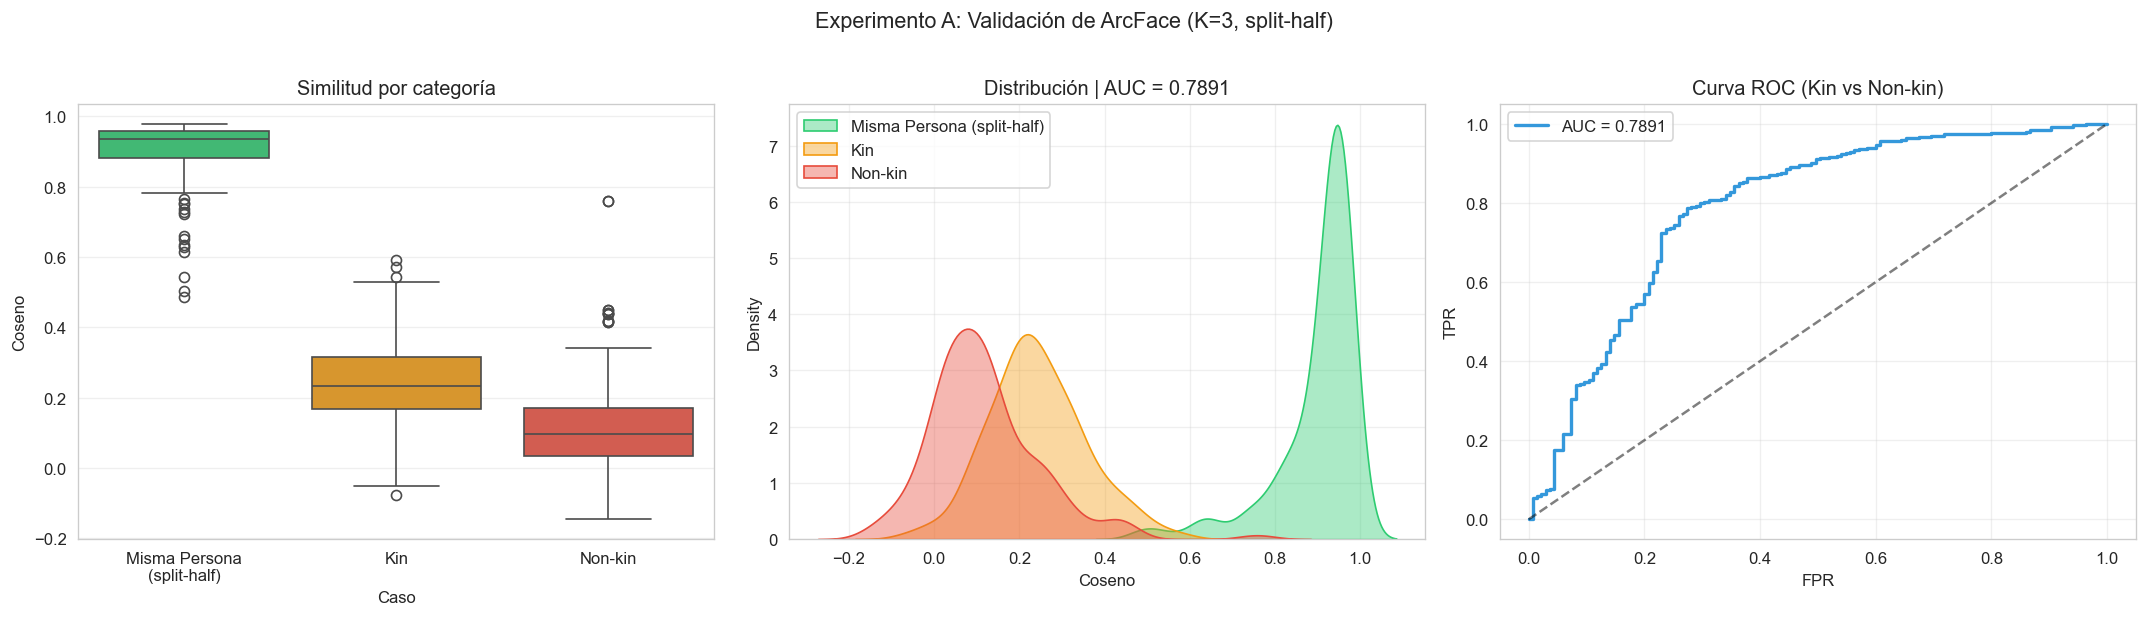

In [ ]:
# ============================================================
# EXPERIMENTO A: KIN vs NON-KIN (embeddings promediados)
# ============================================================

N_A = 300
scores_kin, scores_non, scores_misma = [], [], []

print("  Procesando...")
intentos = 0

while len(scores_kin) < N_A and intentos < N_A * 5:
    intentos += 1
    row = df.sample(1).iloc[0]
    fam = row['familia']
    if fam not in familias_disco: continue

    mid_h = mid_desde_ruta(row['p2'])
    mid_p = mid_desde_ruta(row['p1_papa'])
    mid_m = mid_desde_ruta(row['p1_mama'])
    if not mid_h or not mid_p or not mid_m: continue

    # Embeddings promediados (K=3)
    v_h = embedding_promedio(fam, mid_h, 3)
    v_p = embedding_promedio(fam, mid_p, 3)
    v_m = embedding_promedio(fam, mid_m, 3)
    if v_h is None or v_p is None or v_m is None: continue

    # Kin: padre-hijo y madre-hijo por separado
    scores_kin.append(coseno(v_p, v_h))
    scores_kin.append(coseno(v_m, v_h))

    # Misma persona: split-half (mitad vs mitad de fotos)
    fotos_h = listar_fotos(RUTA_FIDS / fam / mid_h)
    if len(fotos_h) >= 4:
        random.shuffle(fotos_h)
        mitad = len(fotos_h) // 2
        half_a = fotos_h[:mitad]
        half_b = fotos_h[mitad:]

        embs_a = [obtener_embedding(fam, mid_h, f) for f in half_a]
        embs_b = [obtener_embedding(fam, mid_h, f) for f in half_b]
        embs_a = [e for e in embs_a if e is not None]
        embs_b = [e for e in embs_b if e is not None]

        if embs_a and embs_b:
            avg_a = np.mean(embs_a, axis=0).astype(np.float32)
            avg_a = avg_a / (np.linalg.norm(avg_a) + 1e-8)
            avg_b = np.mean(embs_b, axis=0).astype(np.float32)
            avg_b = avg_b / (np.linalg.norm(avg_b) + 1e-8)
            scores_misma.append(coseno(avg_a, avg_b))

    # Non-kin: hijo vs persona de otra familia
    fam_ex = random.choice(list(familias_disco - {fam}))
    mids_ex = [m for m in os.listdir(RUTA_FIDS / fam_ex)
               if os.path.isdir(RUTA_FIDS / fam_ex / m)]
    if not mids_ex: continue
    mid_ex = random.choice(mids_ex)
    v_ex = embedding_promedio(fam_ex, mid_ex, 3)
    if v_ex is None: continue
    scores_non.append(coseno(v_h, v_ex))
    scores_non.append(coseno(v_h, v_ex))

    if len(scores_kin) % 100 == 0:
        print(f"    {len(scores_kin)} pares...")

# ── Métricas ──────────────────────────────────────────────────

y_true   = [1] * len(scores_kin) + [0] * len(scores_non)
y_scores = scores_kin + scores_non
auc      = roc_auc_score(y_true, y_scores)
stat, pval = mannwhitneyu(scores_kin, scores_non, alternative='greater')

print(f"\n{'='*60}")
print(f"{'EXPERIMENTO A: KIN vs NON-KIN':^60}")
print(f"{'='*60}")
print(f"  {'Misma persona (split-half):':<30} n={len(scores_misma):<6} media={np.mean(scores_misma):.4f} ± {np.std(scores_misma):.4f}")
print(f"  {'Kin:':<30} n={len(scores_kin):<6} media={np.mean(scores_kin):.4f} ± {np.std(scores_kin):.4f}")
print(f"  {'Non-kin:':<30} n={len(scores_non):<6} media={np.mean(scores_non):.4f} ± {np.std(scores_non):.4f}")
print(f"  {'─'*50}")
print(f"  {'AUC:':<30} {auc:.4f}")
print(f"  {'Mann-Whitney p-value:':<30} {pval:.4e}")
print(f"{'='*60}")

# ── Gráficas ──────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Boxplot
data_box = pd.DataFrame([
    *[{'Caso': 'Misma Persona\n(split-half)', 'Coseno': s} for s in scores_misma],
    *[{'Caso': 'Kin', 'Coseno': s} for s in scores_kin],
    *[{'Caso': 'Non-kin', 'Coseno': s} for s in scores_non],
])
orden = ['Misma Persona\n(split-half)', 'Kin', 'Non-kin']
colores = ['#2ecc71', '#f39c12', '#e74c3c']
sns.boxplot(data=data_box, x='Caso', y='Coseno', order=orden,
            palette=colores, ax=axes[0])
axes[0].set_title('Similitud por categoría')
axes[0].grid(axis='y', alpha=0.3)

# KDE
for caso, col in zip(orden, colores):
    sub = data_box[data_box['Caso'] == caso]['Coseno']
    if len(sub) > 1:
        sns.kdeplot(sub, fill=True, label=caso.replace('\n', ' '),
                    color=col, alpha=0.4, ax=axes[1])
axes[1].set_title(f'Distribución | AUC = {auc:.4f}')
axes[1].legend()
axes[1].grid(alpha=0.3)

# ROC
fpr, tpr, _ = roc_curve(y_true, y_scores)
axes[2].plot(fpr, tpr, color='#3498db', lw=2, label=f'AUC = {auc:.4f}')
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[2].set_title('Curva ROC (Kin vs Non-kin)')
axes[2].set_xlabel('FPR')
axes[2].set_ylabel('TPR')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('Experimento A: Validación de ArcFace (K=3, split-half)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Experimento B: Similitud por tipo de relación

  Procesando tríadas...
    50/200 tríadas...
    100/200 tríadas...
    150/200 tríadas...
    200/200 tríadas...

            EXPERIMENTO B: POR TIPO DE RELACIÓN             
     Relación   N  Media    Std     Mín    Máx
 Padre → Hijo 144 0.2833 0.1184 -0.0417 0.5760
 Padre → Hija  56 0.2324 0.1212 -0.0223 0.6506
 Madre → Hija  56 0.2157 0.1388 -0.0336 0.5205
 Madre → Hijo 144 0.2030 0.1096 -0.0376 0.4648
Padre ↔ Madre 200 0.1334 0.1141 -0.1694 0.4540
No parentesco 200 0.1131 0.1185 -0.1809 0.7788


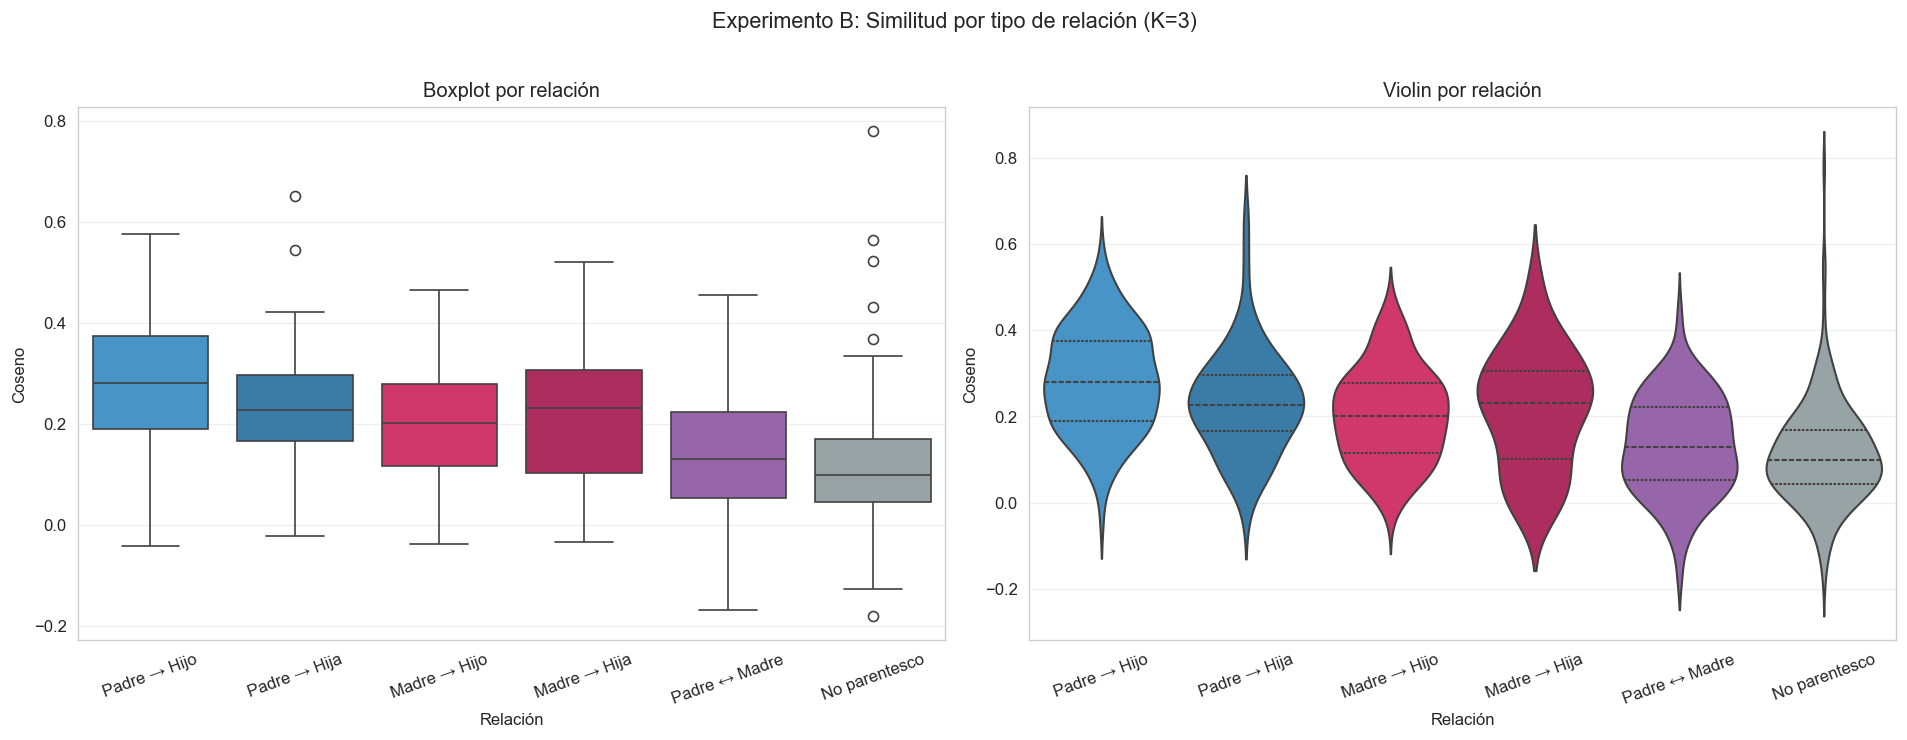

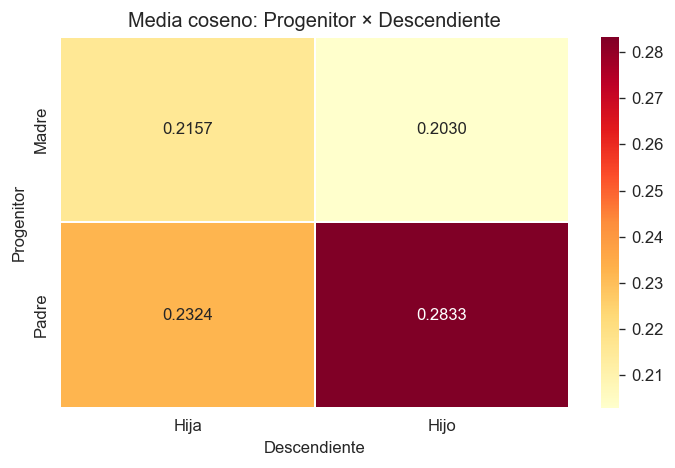

In [ ]:
# ============================================================
# EXPERIMENTO B: SIMILITUD POR TIPO DE RELACIÓN
# ¿Hijos se parecen más al papá o a la mamá?
# ¿Padre→Hijo vs Padre→Hija?
# ============================================================

N_B = 200
relaciones = []
intentos = 0

print("  Procesando tríadas...")

while len(relaciones) // 4 < N_B and intentos < N_B * 10:
    intentos += 1
    row = df.sample(1).iloc[0]
    fam = row['familia']
    if fam not in familias_disco: continue

    mid_p = mid_desde_ruta(row['p1_papa'])
    mid_m = mid_desde_ruta(row['p1_mama'])
    mid_h = mid_desde_ruta(row['p2'])
    if not mid_p or not mid_m or not mid_h: continue

    genero = obtener_genero(fam, mid_h)
    if not genero: continue

    # Embeddings promediados K=3
    v_p = embedding_promedio(fam, mid_p, 3)
    v_m = embedding_promedio(fam, mid_m, 3)
    v_h = embedding_promedio(fam, mid_h, 3)
    if v_p is None or v_m is None or v_h is None: continue

    # Non-kin control
    fam_ex = random.choice(list(familias_disco - {fam}))
    mids_ex = [m for m in os.listdir(RUTA_FIDS / fam_ex)
               if os.path.isdir(RUTA_FIDS / fam_ex / m)]
    if not mids_ex: continue
    mid_ex = random.choice(mids_ex)
    v_ex = embedding_promedio(fam_ex, mid_ex, 3)
    if v_ex is None: continue

    relaciones.append({'Relación': f'Padre → {genero}',  'Coseno': coseno(v_p, v_h)})
    relaciones.append({'Relación': f'Madre → {genero}',  'Coseno': coseno(v_m, v_h)})
    relaciones.append({'Relación': 'Padre ↔ Madre',      'Coseno': coseno(v_p, v_m)})
    relaciones.append({'Relación': 'No parentesco',       'Coseno': coseno(v_h, v_ex)})

    n = len(relaciones) // 4
    if n % 50 == 0:
        print(f"    {n}/{N_B} tríadas...")

# ── Resultados ────────────────────────────────────────────────

df_b = pd.DataFrame(relaciones)
resumen_b = df_b.groupby('Relación')['Coseno'].agg(
    ['count', 'mean', 'std', 'min', 'max']
).round(4).reset_index()
resumen_b.columns = ['Relación', 'N', 'Media', 'Std', 'Mín', 'Máx']
resumen_b = resumen_b.sort_values('Media', ascending=False)

print(f"\n{'='*60}")
print(f"{'EXPERIMENTO B: POR TIPO DE RELACIÓN':^60}")
print(f"{'='*60}")
imprimir_tabla(resumen_b)

# ── Gráficas ──────────────────────────────────────────────────

orden_b = ['Padre → Hijo', 'Padre → Hija', 'Madre → Hijo', 'Madre → Hija',
           'Padre ↔ Madre', 'No parentesco']
colores_b = ['#3498db', '#2980b9', '#e91e63', '#c2185b', '#9b59b6', '#95a5a6']

# Filtrar solo categorías que existen
existentes = df_b['Relación'].unique()
orden_b  = [o for o in orden_b if o in existentes]
colores_b = colores_b[:len(orden_b)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df_b, x='Relación', y='Coseno', order=orden_b,
            palette=colores_b, ax=axes[0])
axes[0].set_title('Boxplot por relación')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.3)

sns.violinplot(data=df_b, x='Relación', y='Coseno', order=orden_b,
               palette=colores_b, inner='quartile', ax=axes[1])
axes[1].set_title('Violin por relación')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Experimento B: Similitud por tipo de relación (K=3)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# ── Heatmap progenitor × descendiente ────────────────────────

pivot = df_b[df_b['Relación'].str.contains('→')].copy()
pivot['Progenitor']   = pivot['Relación'].apply(lambda x: x.split(' →')[0])
pivot['Descendiente'] = pivot['Relación'].apply(lambda x: x.split('→ ')[1])
tabla_heat = pivot.groupby(['Progenitor', 'Descendiente'])['Coseno'].mean().unstack()

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(tabla_heat, annot=True, fmt='.4f', cmap='YlOrRd',
            linewidths=1, ax=ax)
ax.set_title('Media coseno: Progenitor × Descendiente')
plt.tight_layout()
plt.show()